# 03 · Backtest: would the model have made money?

**Setup.** A retail investor applies for one minimum lot (about ₹15,000) in the IPOs a strategy picks,
and sells at the listing-day open. Every decision uses only what was known before listing:
walk-forward predictions from `02_modeling`.

**Allotment is a lottery.** In an oversubscribed IPO, a one-lot retail applicant gets shares with
odds of roughly 1 / retail subscription. A 100x IPO lists high, but you get shares about 1 time in 100.
So each application is worth `gain × ₹15,000 × allotment odds` in expectation.

**No peeking.** Every threshold was chosen on 2019–2023; 2024–2026 is scored once.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from src.backtest import LOT_VALUE, THRESHOLDS, allotment_chance, load_backtest_frame, strategies, summarize
from src.viz import AQUA, BLUE, NEUTRAL, ORANGE, TEXT_SECONDARY, apply_style, save

apply_style()
pd.set_option("display.float_format", "{:,.1f}".format)
rupees = mtick.FuncFormatter(lambda v, _: f"₹{v:,.0f}")

df = load_backtest_frame()
dev = df[df["year"].between(2019, 2023)]
test = df[df["year"] >= 2024].sort_values("listing_date").reset_index(drop=True)
chosen, plans = strategies(dev, test)
chosen

{'model_threshold': -2.0,
 'lookup_threshold': -10.0,
 'subscription_cutoff': 0.0}

Thresholds picked on 2019–2023:
- **Model:** apply when the predicted gain is at least −2%.
- **Same-bucket lookup:** its best threshold applies to every IPO, so it adds nothing.
- **Subscription cutoff:** the best cutoff on 2019–2023 was 0x. No pure subscription cutoff beat
  applying to everything, which is a useful result in itself.

## 1. Results

In [2]:
rows = []
for period, frame in [("2019–2023", dev), ("2024–2026", test)]:
    for name, rule, mask in plans:
        rows.append({"period": period, "strategy": name, "rule": rule, **summarize(frame, mask(frame))})
results = pd.DataFrame(rows)
cols = ["strategy", "rule", "applied", "hit_rate", "avg_gain", "worst_gain", "expected_allotments",
        "expected_profit", "losses_avoided"]
results[results["period"] == "2024–2026"][cols].set_index("strategy")

,rule,applied,hit_rate,avg_gain,worst_gain,expected_allotments,expected_profit,losses_avoided
strategy,,,,,,,,
Apply to every IPO,always,202,67.8,16.2,-39.6,62.7,"24,506.0",0
Rule: subscribed 30x or more,sub_total >= 30,98,89.8,31.7,-34.6,5.5,"21,505.0",42
Rule: tuned subscription cutoff,sub_total >= 0,202,67.8,16.2,-39.6,62.7,"24,506.0",0
Lookup: same-bucket median,bucket median >= -10%,202,67.8,16.2,-39.6,62.7,"24,506.0",0
Model: random forest,predicted gain >= -2%,187,70.6,17.8,-39.6,52.6,"30,588.1",9


In [3]:
results[results["period"] == "2019–2023"][cols].set_index("strategy")

,rule,applied,hit_rate,avg_gain,worst_gain,expected_allotments,expected_profit,losses_avoided
strategy,,,,,,,,
Apply to every IPO,always,192,73.4,25.3,-23.7,60.8,"57,367.2",0
Rule: subscribed 30x or more,sub_total >= 30,83,97.6,53.4,-6.3,5.6,"34,678.5",41
Rule: tuned subscription cutoff,sub_total >= 0,192,73.4,25.3,-23.7,60.8,"57,367.2",0
Lookup: same-bucket median,bucket median >= -10%,192,73.4,25.3,-23.7,60.8,"57,367.2",0
Model: random forest,predicted gain >= -2%,166,78.9,29.8,-23.7,42.8,"67,631.7",15


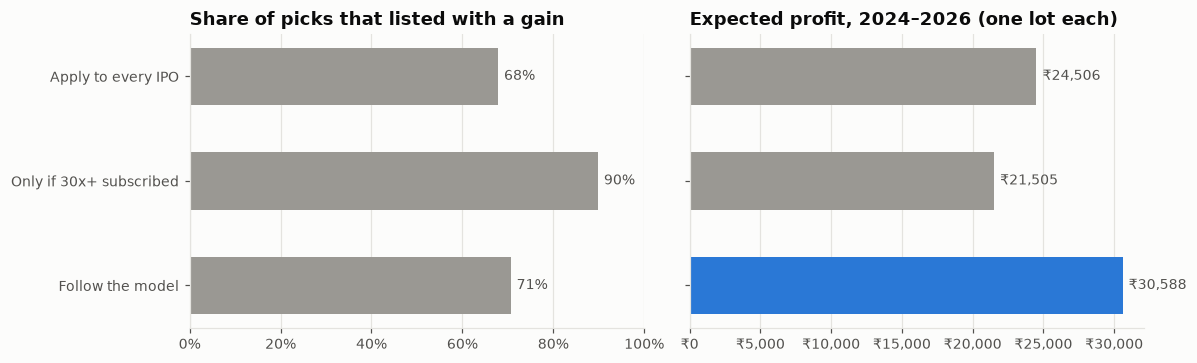

In [4]:
show = ["Apply to every IPO", "Rule: subscribed 30x or more", "Model: random forest"]
out = results[(results["period"] == "2024–2026") & results["strategy"].isin(show)].set_index("strategy").loc[show]
labels = ["Apply to every IPO", "Only if 30x+ subscribed", "Follow the model"]

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.4))
left.barh(labels, out["hit_rate"], color=NEUTRAL, height=0.55)
left.set_title("Share of picks that listed with a gain")
left.xaxis.set_major_formatter(mtick.PercentFormatter())
left.set_xlim(0, 100)
right.barh(labels, out["expected_profit"], color=[NEUTRAL, NEUTRAL, BLUE], height=0.55)
right.set_title("Expected profit, 2024–2026 (one lot each)")
right.xaxis.set_major_formatter(rupees)
for ax, col, fmt in [(left, "hit_rate", "{:.0f}%"), (right, "expected_profit", "₹{:,.0f}")]:
    ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True); ax.invert_yaxis()
    for y, v in enumerate(out[col]):
        ax.annotate(fmt.format(v), (v, y), xytext=(4, 0), textcoords="offset points", va="center",
                    fontsize=9, color=TEXT_SECONDARY)
right.set_yticklabels([])
fig.tight_layout()
save(fig, "12_strategy_comparison")
plt.show()

**The 30x rule has the best hit rate and the worst profit.** Its picks list high, but they are so
oversubscribed that a retail applicant expects only about 5 allotments across 98 applications.
The model applies more widely and skips only the IPOs it expects to list flat or down.

## 2. Profit over time (2024–2026)

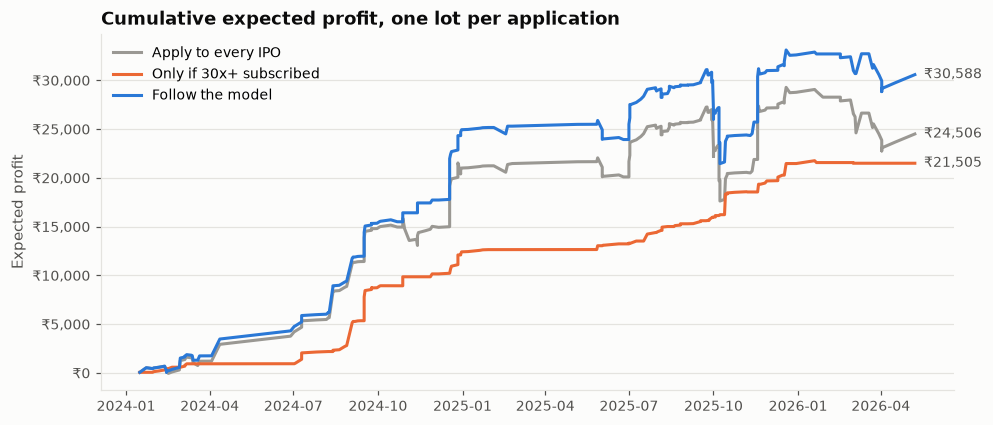

In [5]:
odds = test["sub_rii"].map(allotment_chance)
per_ipo = test["target_gain_pct"] / 100 * LOT_VALUE * odds
masks = {name: mask(test) for name, _, mask in plans}

fig, ax = plt.subplots(figsize=(10, 4.2))
for name, color, label in [("Apply to every IPO", NEUTRAL, "Apply to every IPO"),
                           ("Rule: subscribed 30x or more", ORANGE, "Only if 30x+ subscribed"),
                           ("Model: random forest", BLUE, "Follow the model")]:
    path = per_ipo.where(masks[name], 0).cumsum()
    ax.plot(test["listing_date"], path, color=color, linewidth=2, label=label)
    ax.annotate(f"₹{path.iloc[-1]:,.0f}", (test["listing_date"].iloc[-1], path.iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=TEXT_SECONDARY)
ax.yaxis.set_major_formatter(rupees)
ax.set_title("Cumulative expected profit, one lot per application")
ax.set_ylabel("Expected profit")
ax.legend(loc="upper left")
save(fig, "13_cumulative_profit")
plt.show()

## 3. Is the edge real or luck? (paired bootstrap)

In [6]:
model_profit = per_ipo.where(masks["Model: random forest"], 0).to_numpy()
rng = np.random.default_rng(0)
rows = []
for name in ["Apply to every IPO", "Rule: subscribed 30x or more", "Rule: tuned subscription cutoff"]:
    diff = model_profit - per_ipo.where(masks[name], 0).to_numpy()
    boots = np.array([rng.choice(diff, len(diff)).sum() for _ in range(10_000)])
    rows.append({"model vs": name, "extra profit": diff.sum(), "95% CI low": np.percentile(boots, 2.5),
                 "95% CI high": np.percentile(boots, 97.5), "resamples where model loses (%)": (boots <= 0).mean() * 100})
pd.DataFrame(rows).set_index("model vs")

,extra profit,95% CI low,95% CI high,resamples where model loses (%)
model vs,,,,
Apply to every IPO,"6,082.1","1,240.7","11,977.9",0.4
Rule: subscribed 30x or more,"9,083.1","-10,926.5","28,820.9",18.5
Rule: tuned subscription cutoff,"6,082.1","1,426.9","12,089.1",0.2


Resampling the 202 IPOs 10,000 times:
- **Against applying to everything,** the model's extra profit stays positive in over 99% of resamples.
- **Against the 30x rule,** the model still earns more on average, but the interval includes zero.
  So that win is not proven.

## 4. What the model skipped in 2024–2026

In [7]:
skipped = test[~masks["Model: random forest"]]
skipped[["ipo_name", "listing_date", "sub_total", "random_forest", "target_gain_pct"]].rename(columns={
    "sub_total": "subscription (x)", "random_forest": "predicted gain %", "target_gain_pct": "actual gain %"})

,ipo_name,listing_date,subscription (x),predicted gain %,actual gain %
9,Entero Healthcare Solutions Limited,2024-02-16,1.5,-3.9,-2.3
19,Popular Vehicles & Services Ltd,2024-03-19,1.2,-3.5,-2.0
56,Godavari Biorefineries Limited,2024-10-30,1.8,-5.5,-12.5
57,Afcons Infrastructure Limited,2024-11-04,2.6,-3.3,-8.0
58,Sagility India Limited,2024-11-12,3.2,-3.3,3.5
59,ACME Solar Holdings Limited,2024-11-13,2.8,-4.0,-13.1
61,Niva Bupa Health Insurance Company Limited,2024-11-14,1.8,-4.7,5.6
62,Zinka Logistics Solution Limited (BlackBuck),2024-11-22,1.9,-4.6,2.2
63,NTPC Green Energy Limited,2024-11-27,2.4,-3.8,3.2
65,Suraksha Diagnostic Limited,2024-12-06,1.3,-3.4,-0.7


In [8]:
print(f"skipped {len(skipped)} IPOs: {(skipped.target_gain_pct < 0).sum()} listed below offer, "
      f"{(skipped.target_gain_pct > 0).sum()} above, all below +6%")

skipped 15 IPOs: 9 listed below offer, 5 above, all below +6%


## 5. How sensitive is this to the threshold?

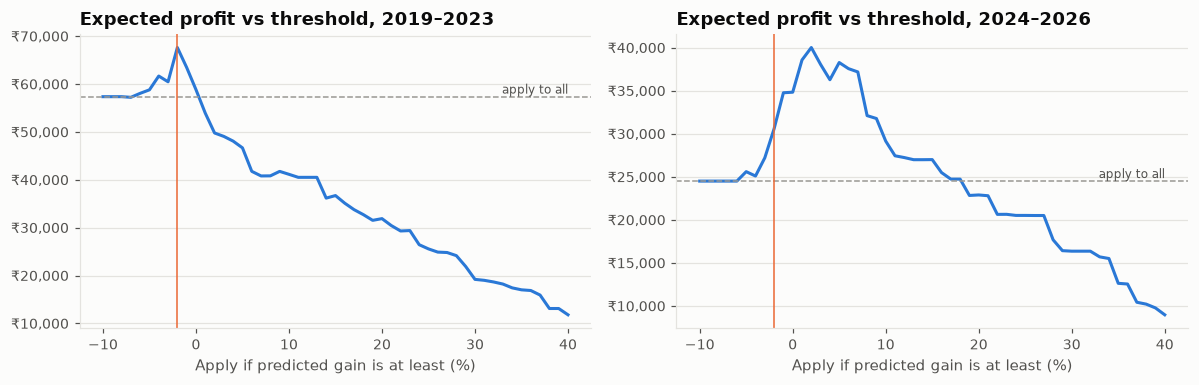

In [9]:
curve = pd.DataFrame({
    "threshold": THRESHOLDS,
    "2019–2023": [summarize(dev, dev["random_forest"] >= t)["expected_profit"] for t in THRESHOLDS],
    "2024–2026": [summarize(test, test["random_forest"] >= t)["expected_profit"] for t in THRESHOLDS],
}).set_index("threshold")
baseline = {"2019–2023": summarize(dev, dev["random_forest"] > -1e9)["expected_profit"],
            "2024–2026": summarize(test, test["random_forest"] > -1e9)["expected_profit"]}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for ax, period in zip(axes, ["2019–2023", "2024–2026"]):
    ax.plot(curve.index, curve[period], color=BLUE, linewidth=2)
    ax.axhline(baseline[period], color=NEUTRAL, linewidth=1, linestyle="--")
    ax.text(curve.index.max(), baseline[period], " apply to all", va="bottom", ha="right", fontsize=8, color=TEXT_SECONDARY)
    ax.axvline(chosen["model_threshold"], color=ORANGE, linewidth=1)
    ax.set_title(f"Expected profit vs threshold, {period}")
    ax.yaxis.set_major_formatter(rupees)
    ax.set_xlabel("Apply if predicted gain is at least (%)")
fig.tight_layout()
save(fig, "14_threshold_sensitivity")
plt.show()

The 2019–2023 curve is spiky: the chosen −2% sits on a sharp peak, and any threshold from −4% to 0%
beats applying to everything, while +1% or higher already falls below it. That spikiness is
small-sample noise, so the exact −2% shouldn't be over-read.

On 2024–2026, every threshold from −5% up to about +17% beats applying to everything, and the best
would have been around +2%. In a lower-gain period, being a little pickier paid off; the −2% picked
on earlier data was on the cautious side, not a lucky choice.

## Caveats

- Allotment odds use 1 / retail subscription, a standard approximation; actual odds depend on
  how many applicants bid for more than one lot.
- Profit assumes selling at the listing-day open. Brokerage, taxes and slippage are ignored;
  for a one-lot retail trade they are small next to listing-day moves.
- 2024–2026 is a single period of 202 IPOs. The edge over applying to everything is significant;
  the edge over the 30x rule is not.